# **Decision Tree Regression - California Housing Dataset**

## **Project Overview**

This project uses a Decision Tree Regressor to predict house values using the California Housing dataset.

The model learns patterns from housing features and predicts the median house value.

### **Objectives**

- Load and explore the dataset.
- Perform Exploratory Data Analysis (EDA).
- Split the dataset into training and testing sets.
- Train a Decision Tree Regressor.
- Evaluate model performance using regression metrics.
- Visualize predictions, residuals, and feature importance.
- Predict the house value for a sample.

## **Import Libraries**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

## **1. Load the Dataset**

The California Housing dataset contains information about housing districts in California.

It includes features such as median income, average house age, and average number of rooms.

The target variable represents the median house value in units of $100,000.

In [9]:
# Load the California Housing dataset

data = fetch_california_housing(as_frame=True)

# Separate features and target
X = data.data
y = data.target

print("Dataset loaded successfully.")
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Dataset loaded successfully.
Features shape: (20640, 8)
Target shape: (20640,)


In [10]:
# Display the first five rows

X.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [11]:
# Display dataset information

print("Number of rows:", X.shape[0])
print("Number of columns:", X.shape[1])

print("\nDataset information:")
X.info()

Number of rows: 20640
Number of columns: 8

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
dtypes: float64(8)
memory usage: 1.3 MB


In [12]:
# Check missing values in each feature

missing_values = X.isnull().sum()

print("Missing values in each feature:")
print(missing_values)

print("\nTotal missing values:", missing_values.sum())

Missing values in each feature:
MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
dtype: int64

Total missing values: 0


## **Analyze Target Distribution**

Before training the model, let's examine the distribution of median house values.

This helps us understand how house values are distributed and identify any visible skewness or unusual patterns.

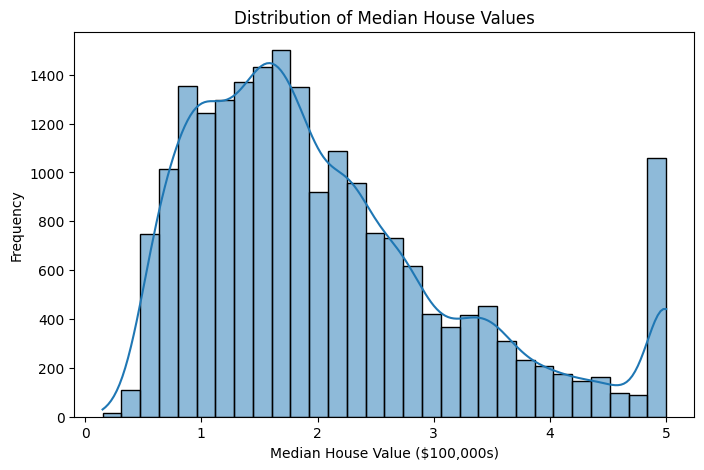

In [15]:
# Visualize the distribution of house values

plt.figure(figsize=(8, 5))

sns.histplot(y, bins=30, edgecolor="black", kde=True)

plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value ($100,000s)")
plt.ylabel("Frequency")

plt.show()

## **Analyze Feature Correlation**

Correlation measures the strength and direction of the linear relationship between numerical variables.

I will use a heatmap to examine the relationships between the input features and the target variable.

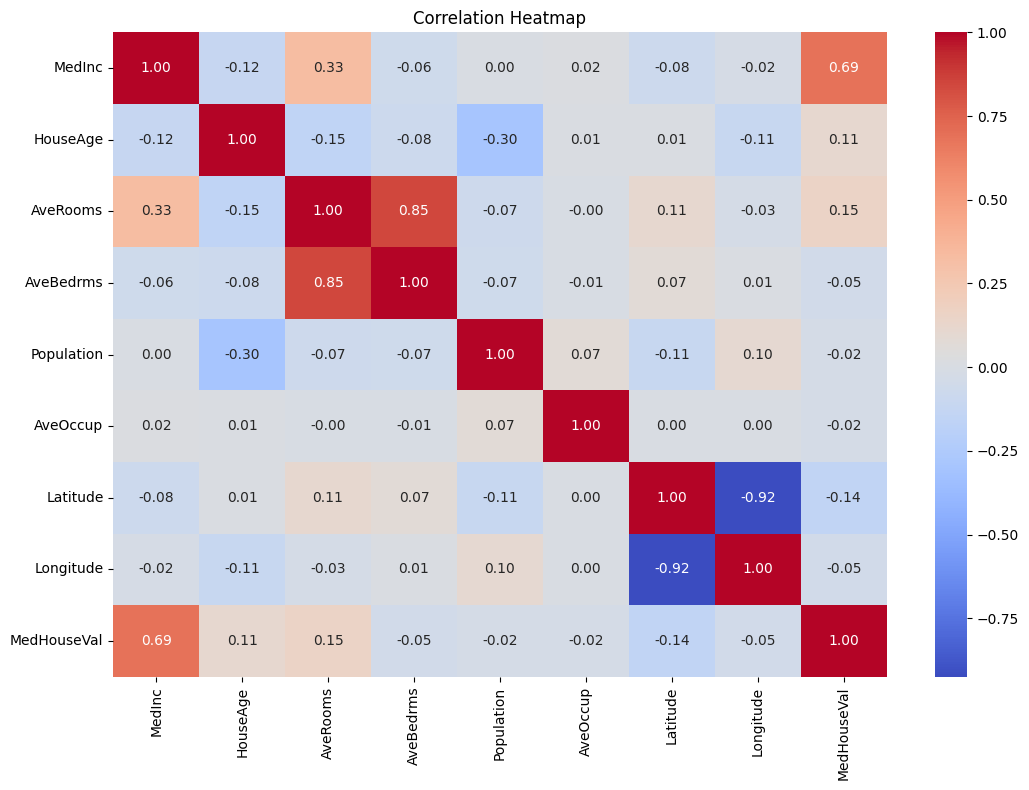

In [17]:
# Combine features and target for correlation analysis

df = X.copy()
df["MedHouseVal"] = y

# Calculate correlation matrix
correlation_matrix = df.corr()

# Visualize correlations using Seaborn
plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


## **5. Train-Test Split**

Let's divide the dataset into training and testing sets.

- Training set: 80% of the data, used to train the model.
- Testing set: 20% of the data, used to evaluate the model.

The `random_state=42` parameter ensures that the same split can be reproduced.

In [18]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (16512, 8)
Testing features: (4128, 8)
Training target: (16512,)
Testing target: (4128,)


## **6. Model Building**

Decision Tree Regression is a supervised machine learning algorithm used to predict continuous numerical values.

It divides the data into smaller groups using feature-based conditions and predicts a value for each final group.

I will use `max_depth=5` to limit the tree's depth and help control overfitting.

In [19]:
# Create the Decision Tree Regressor

regressor = DecisionTreeRegressor(
    max_depth=5,
    random_state=42
)

print("Decision Tree Regressor created successfully.")

Decision Tree Regressor created successfully.


In [20]:
# Train the model

regressor.fit(X_train, y_train)

print("Model training completed successfully.")

Model training completed successfully.


### **Model Predictions**

After training, I will use the model to predict house values for the testing samples.

These predictions will be compared with the actual values to evaluate the model's performance.

In [23]:
# Predict house values for test data

y_pred = regressor.predict(X_test)

print("Predictions generated successfully.")

print("\nFirst 10 actual values:")
print(y_test.head(10).values)

print("\nFirst 10 predicted values:")
print(y_pred[:10])

Predictions generated successfully.

First 10 actual values:
[0.477   0.458   5.00001 2.186   2.78    1.587   1.982   1.575   3.4
 4.466  ]

First 10 predicted values:
[1.16857267 1.27158128 3.19958174 2.20476301 1.64279735 2.33790011
 1.92062128 1.64279735 2.37549582 4.77878874]


## **7. Model Evaluation**

I will evaluate the model using MAE, MSE, RMSE, and R² score.

- MAE: Measures the average absolute prediction error.
- MSE: Measures the average squared prediction error.
- RMSE: Measures prediction error in the target's units.
- R² Score: Measures how well the model explains variation in the target.

Lower error values and a higher R² score generally indicate better performance.

In [26]:
# Calculate model evaluation metrics

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R² Score:", r2)

Mean Absolute Error: 0.5222592972077786
Mean Squared Error: 0.5245146178314735
Root Mean Squared Error: 0.7242338143386247
R² Score: 0.5997321244428706


## **8. Actual vs Predicted Values**

I will compare the actual house values with the values predicted by the model.

Points closer to the diagonal reference line indicate predictions closer to the actual values.

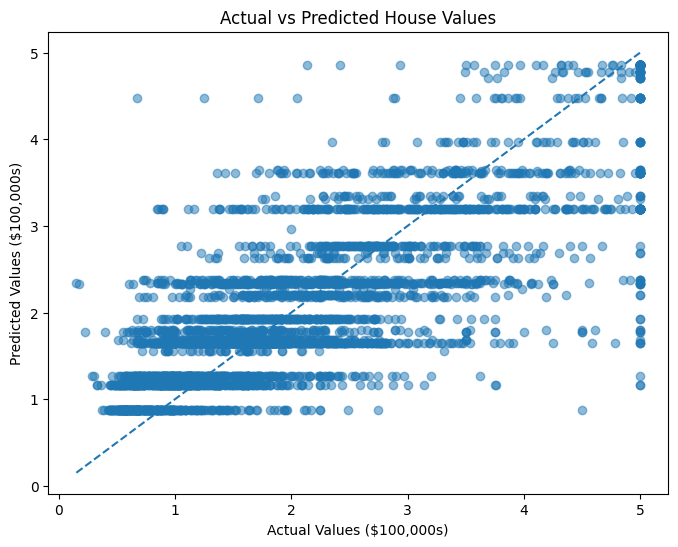

In [27]:
# Visualize actual and predicted values

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.title("Actual vs Predicted House Values")
plt.xlabel("Actual Values ($100,000s)")
plt.ylabel("Predicted Values ($100,000s)")

plt.show()

**Interpretation:** The model captures the general pattern of house prices, but many predictions deviate from the ideal dashed line, indicating prediction errors.

## **9. Residual Analysis**

A residual is the difference between an actual value and its predicted value.

Residual = Actual Value − Predicted Value

I will visualize the residuals to examine the model's prediction errors and identify any visible patterns.

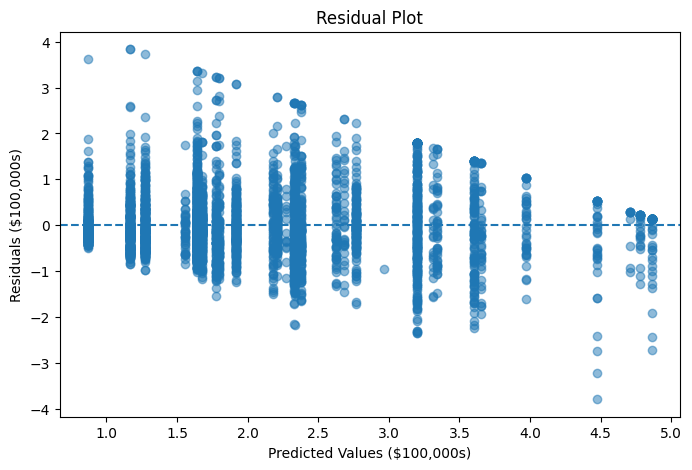

In [28]:
# Calculate residuals

residuals = y_test - y_pred

# Visualize residuals
plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals, alpha=0.5)

plt.axhline(y=0, linestyle="--")

plt.title("Residual Plot")
plt.xlabel("Predicted Values ($100,000s)")
plt.ylabel("Residuals ($100,000s)")

plt.show()

## **10. Decision Tree Visualization**

I will visualize the trained Decision Tree to understand how it makes predictions.

Each internal node represents a decision based on a feature, while the leaf nodes contain predicted numerical values.

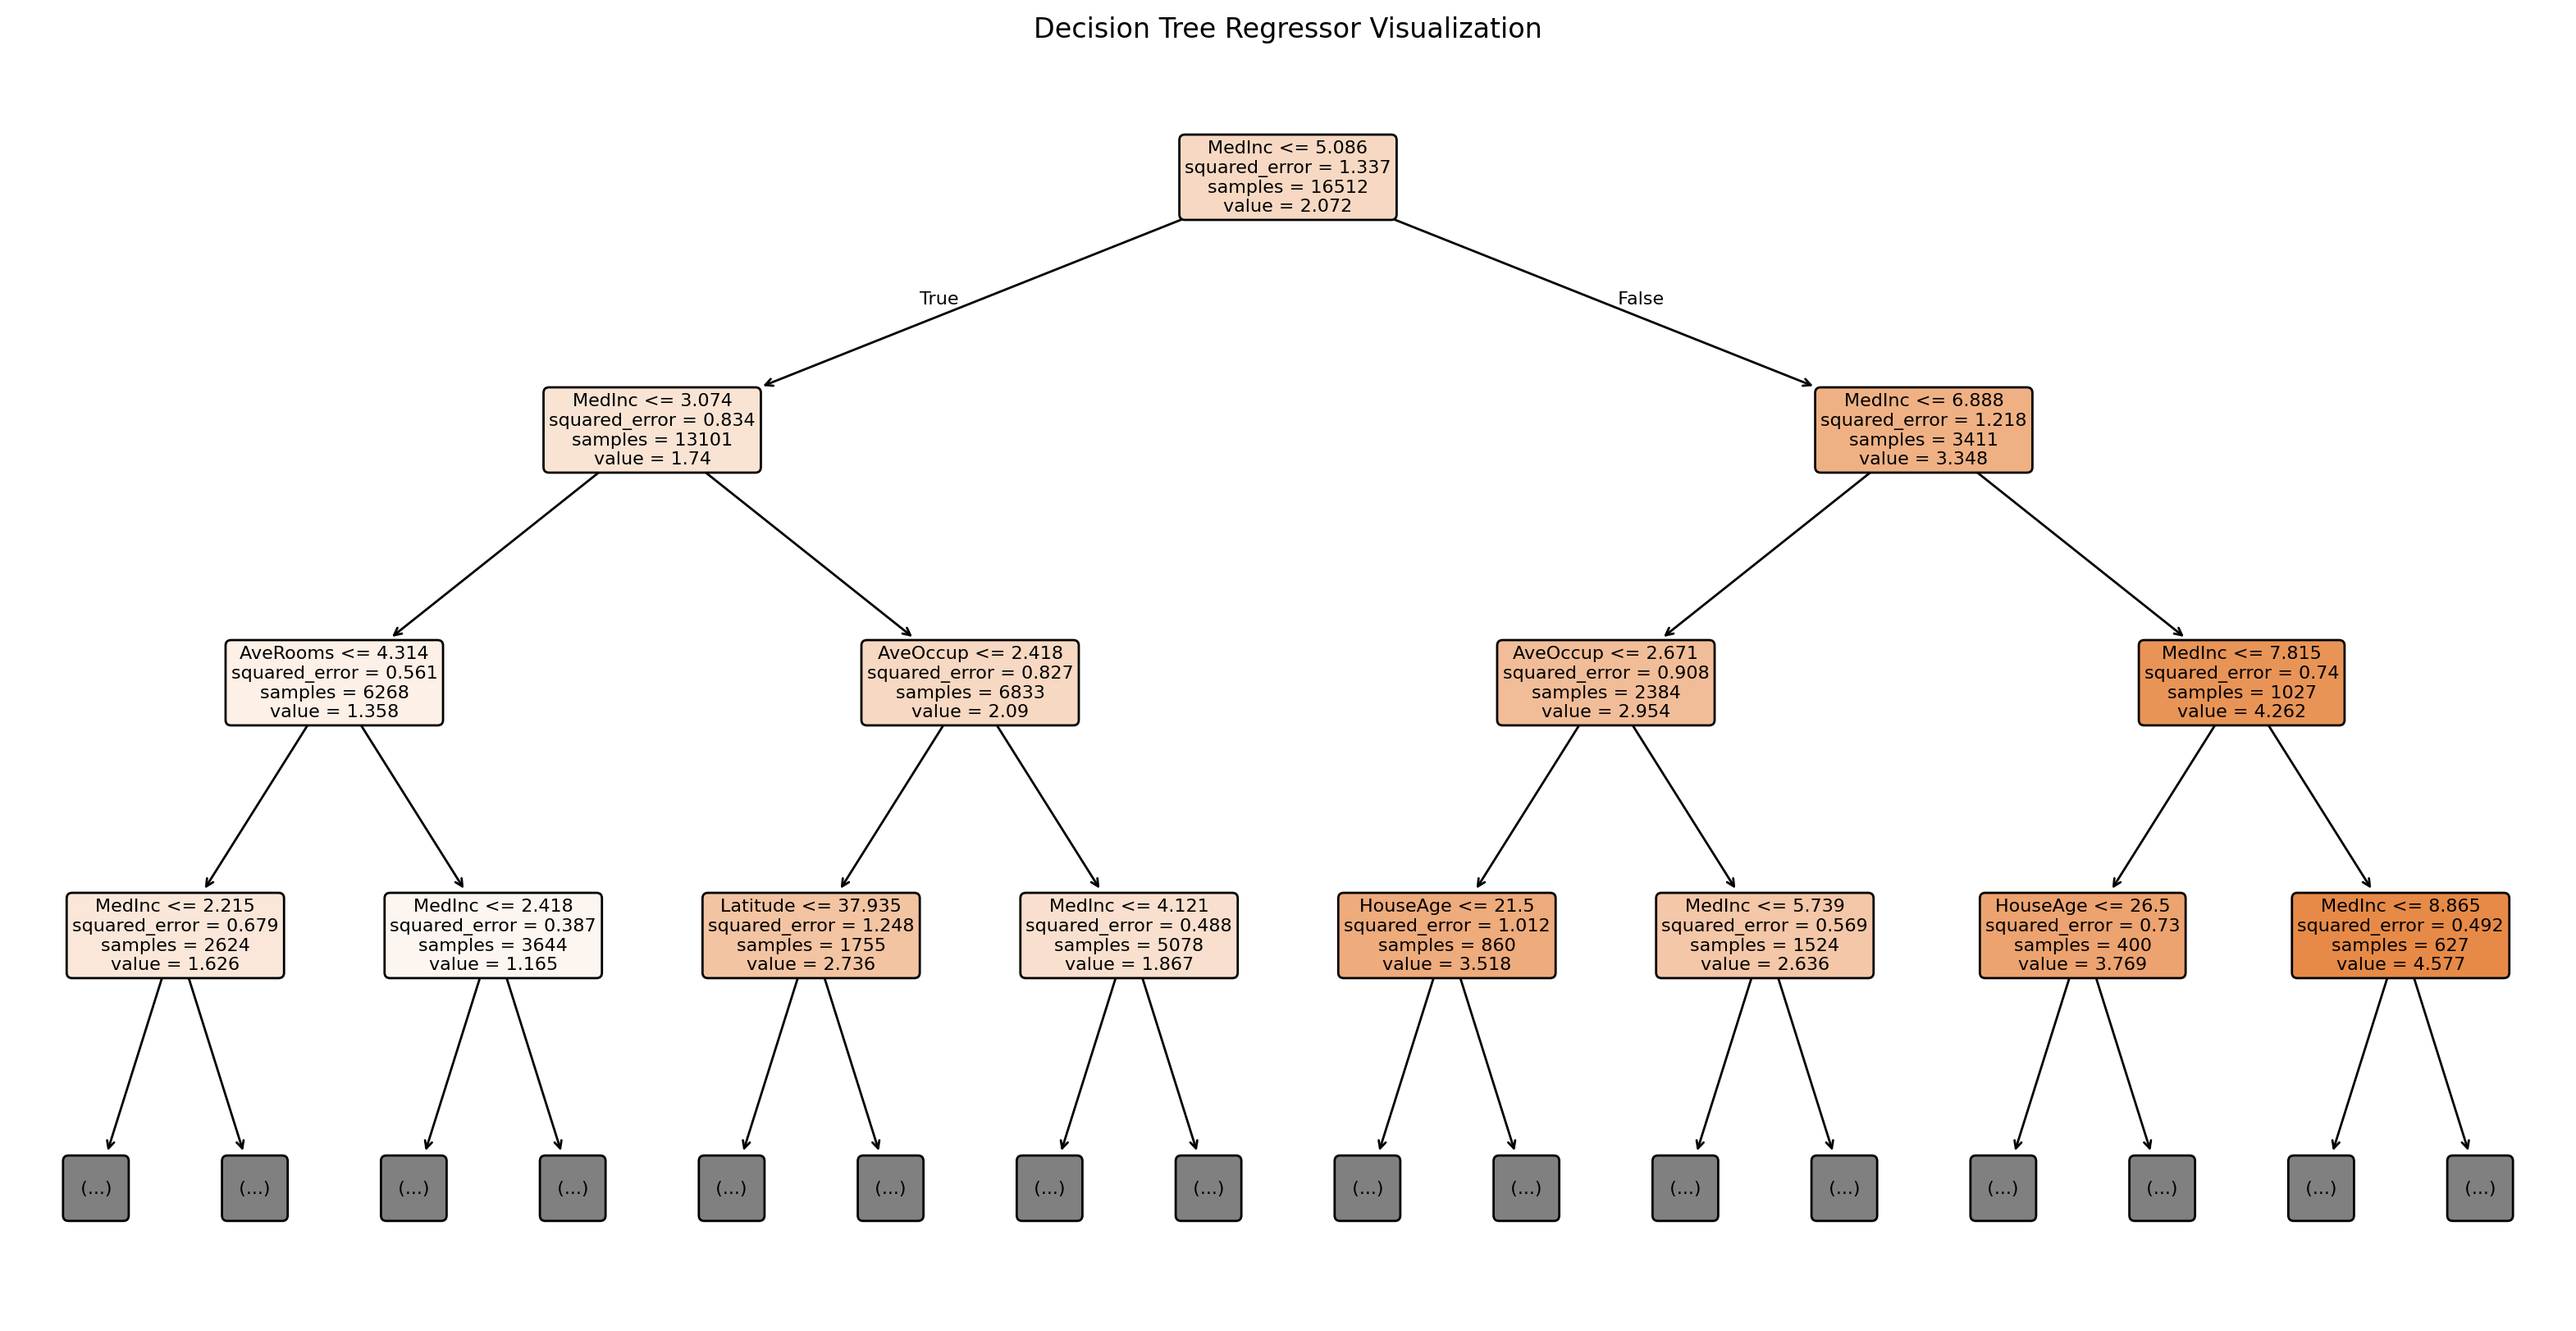

In [31]:
# Visualize the trained Decision Tree

plt.figure(figsize=(20, 10), dpi=200)

plot_tree(
    regressor,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Decision Tree Regressor Visualization")

plt.show()

## **11. Feature Importance**

Feature importance shows how much each feature contributes to the Decision Tree's splitting decisions.

I will rank the features by their importance scores and visualize the top features.

In [32]:
# Calculate feature importance

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": regressor.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(10)

,Feature,Importance
0,MedInc,0.771212
5,AveOccup,0.128407
1,HouseAge,0.041621
2,AveRooms,0.031261
6,Latitude,0.022049
4,Population,0.002485
7,Longitude,0.002097
3,AveBedrms,0.000869


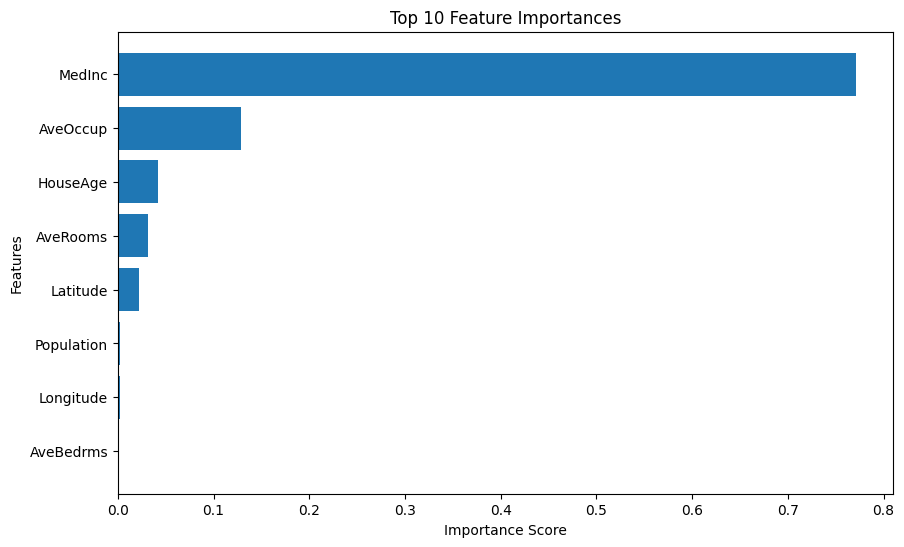

In [33]:
# Plot the top 10 important features

top_features = feature_importance.head(10).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 10 Feature Importances")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.show()

## **13. Conclusion**

In this project, I developed a Decision Tree Regression model using the California Housing dataset.

I explored the dataset, trained the model, and evaluated its performance using MAE, MSE, RMSE, and R² score.

I also visualized actual and predicted values, examined residuals, and identified important features.

The model's performance can be further improved by tuning its hyperparameters and comparing it with other regression algorithms.